In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("smartcart_customers.csv")

In [3]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [4]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

In [5]:
df.shape

(2240, 22)

In [6]:
#missing value
df["Income"] = df["Income"].fillna(df["Income"].median())

#encoding by date 

In [7]:
#Age
df["age"] = 2026-df["Year_Birth"]

In [8]:
#customer joining date
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"],dayfirst= True)
reference_time = df["Dt_Customer"].max()

df["customer_tenure_days"] = (reference_time-df["Dt_Customer"]).dt.days

In [9]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,customer_tenure_days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


In [10]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'age', 'customer_tenure_days'],
      dtype='object')

In [11]:
#total spending

df["total_spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"] 

In [12]:
#children 

df["Total_children"] = df["Kidhome"] + df["Teenhome"]

In [13]:
#Education 

df["Education"].value_counts()

df["Education"] = df["Education"].replace({
    "Graduation":"graduate","2n Cycle":"under_graduate",
    "Basic":"under_graduate",
    "Master":"post_graduate","PhD":"post_graduate"
    
})

In [14]:
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [15]:
df["Living_with"] = df["Marital_Status"].replace({
    "Married":"partner","Together":"partner",
    "Single":"Alone",
    "Divorced":"Alone","Widow":"Alone",
    "Absurd":"Alone","YOLO":"Alone"
    
})

In [16]:
#drop columns

col = ["ID","Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer"]

cols = ["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]
cols_to_drop = col + cols

df_clean = df.drop(columns=cols_to_drop)

In [17]:
df.shape

(2240, 27)

In [18]:
df_clean.columns

Index(['Education', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'age',
       'customer_tenure_days', 'total_spending', 'Total_children',
       'Living_with'],
      dtype='object')

outlier

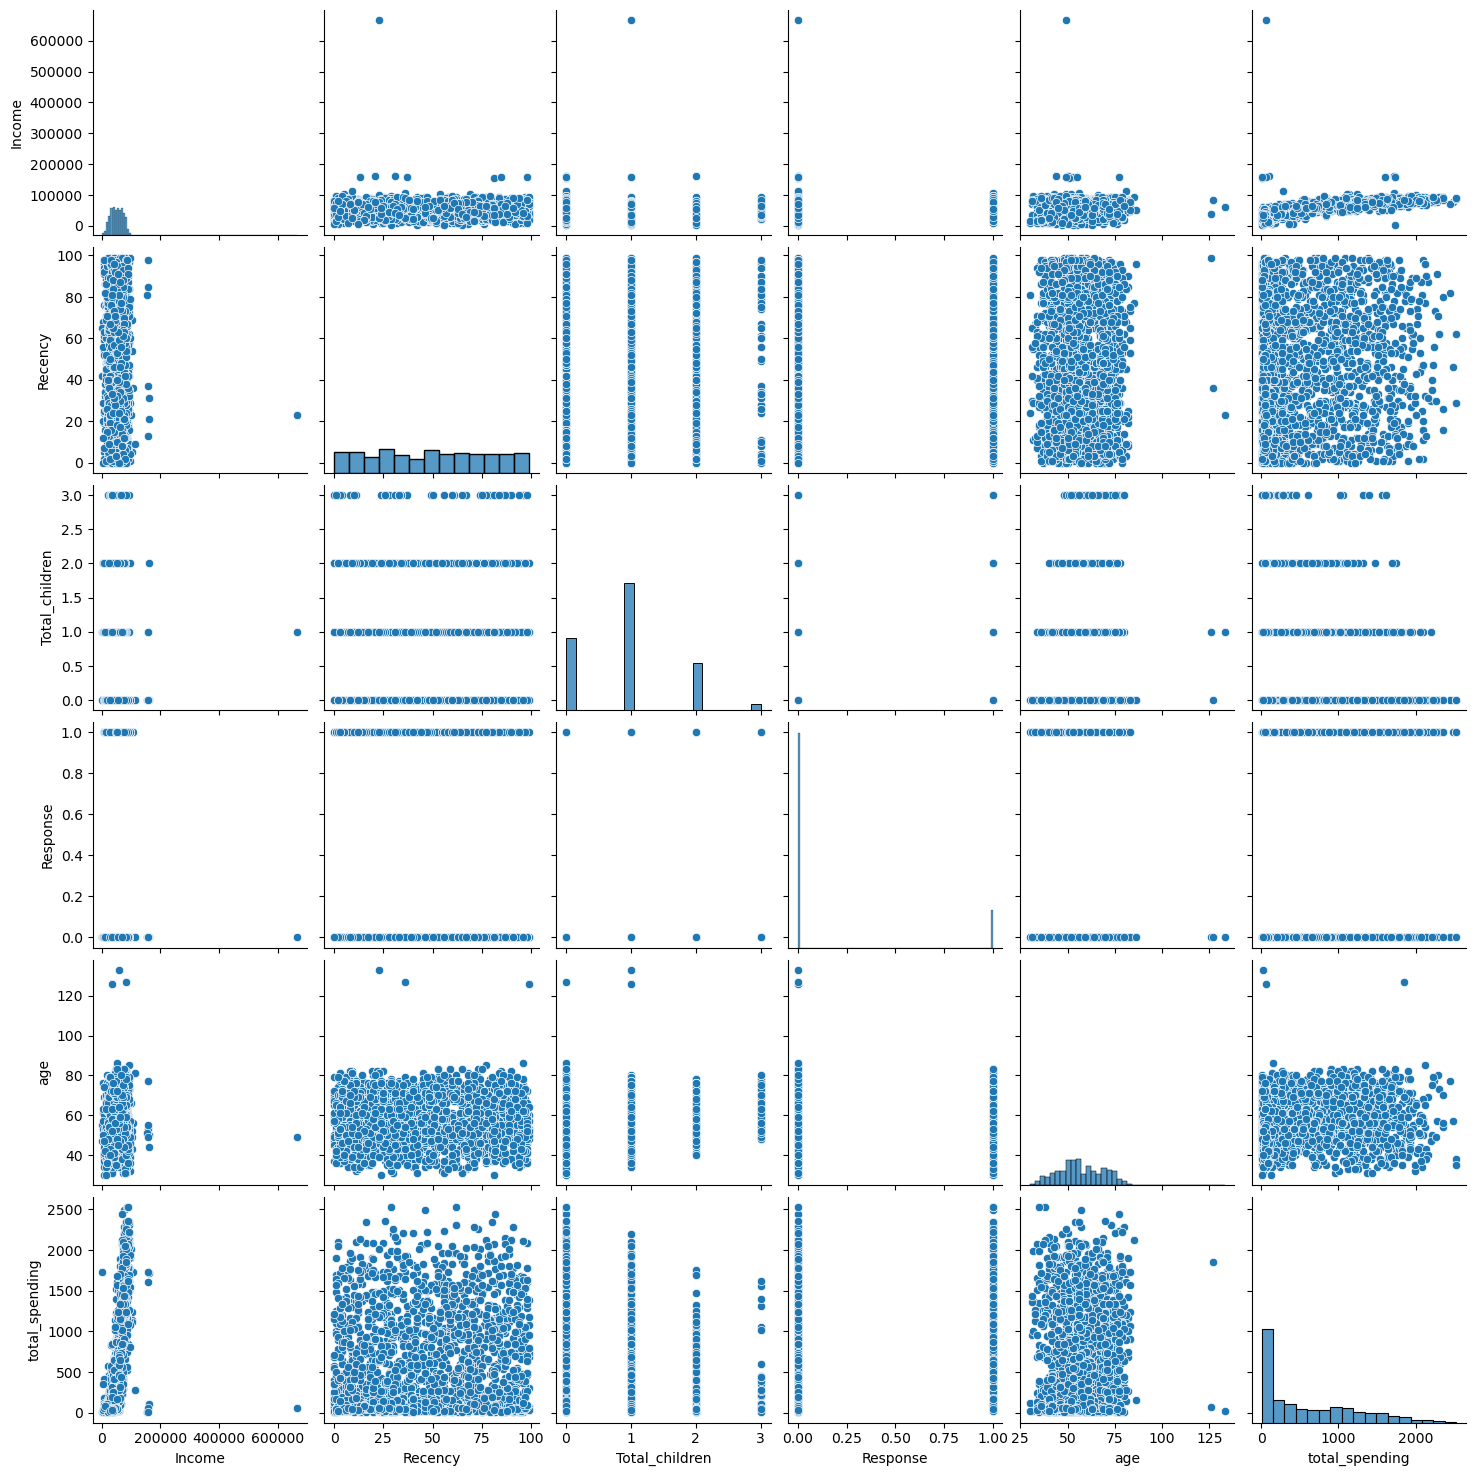

In [19]:
#plot

col = ["Income","Recency","Total_children","Response","age","total_spending"]

sns.pairplot(df_clean[col])

In [20]:
len(df_clean)

2240

In [21]:
#remove outlier

df_clean = df_clean[(df_clean["age"] < 90)]
df_clean = df_clean[(df_clean["Income"] < 600_000)]

In [22]:
len(df_clean)

2236

#heatmap



<Axes: >

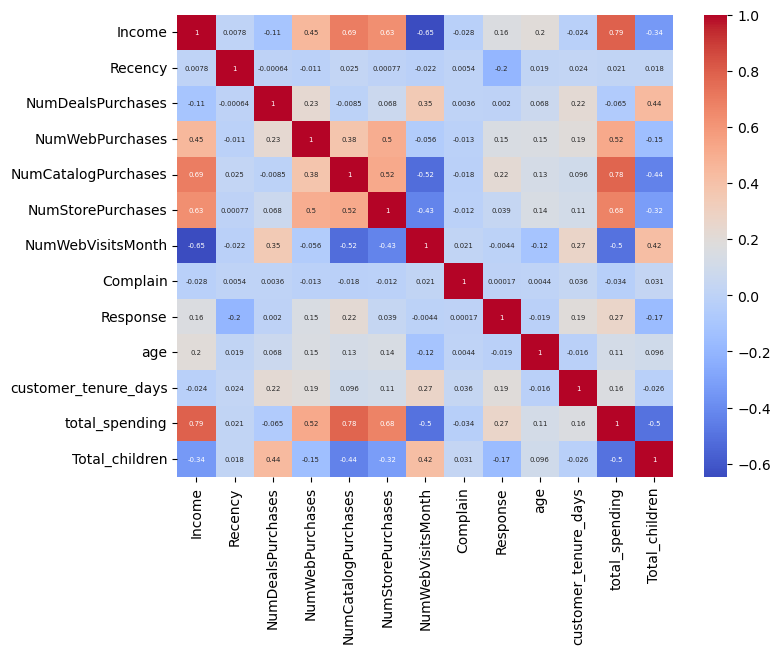

In [23]:
corr = df_clean.corr(numeric_only=True)
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot = True,
    annot_kws = {"size":5},
    cmap = "coolwarm"
)

Encoding

In [24]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder()
cat_col = ["Education","Living_with"]
enc_col = ohe.fit_transform(df_clean[cat_col])

In [25]:
enc_df = pd.DataFrame(enc_col.toarray(),columns= ohe.get_feature_names_out(cat_col),index=df_clean.index)

In [26]:
enc_df = pd.concat([df_clean.drop(columns=cat_col),enc_df],axis=1)

In [27]:
enc_df.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,customer_tenure_days,total_spending,Total_children,Education_graduate,Education_post_graduate,Education_under_graduate,Living_with_Alone,Living_with_partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


In [28]:
X = enc_df

In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scale = scaler.fit_transform(X)



In [30]:
#visualize

from sklearn.decomposition import PCA

pca = PCA(n_components=3)

X_pca = pca.fit_transform(X_scale)

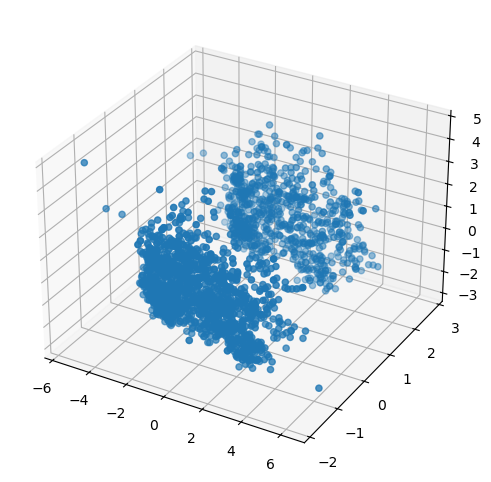

In [31]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111,projection="3d")
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2])


In [32]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss = []

for k in range(1,11):
    kmeans = KMeans(n_clusters=k, random_state = 42 )
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

In [33]:
knee = KneeLocator(range(1,11),wcss,curve="convex",direction = "decreasing")
optimal_k = knee.elbow

In [34]:
print("best_k_values =",optimal_k)

best_k_values = 4


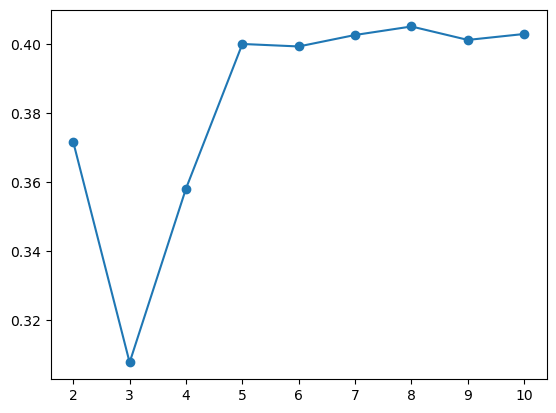

In [35]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2,11):
    kmeans = KMeans(n_clusters=k,random_state=42)
    labels = kmeans.fit_predict(X_pca)
    score =  silhouette_score(X_pca,labels)
    scores.append(score)

plt.plot(range(2,11),scores,marker= "o")
    

In [36]:
#kmeans clusturing 
kmeans = KMeans(n_clusters = 4 , random_state  = 42)
labels = kmeans.fit_predict(X_pca)

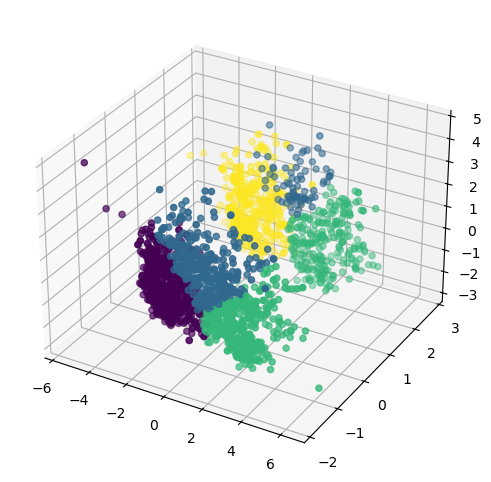

In [37]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111,projection="3d")
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c=labels)

In [38]:
#AgglomerativeClustering
from sklearn.cluster import AgglomerativeClustering

agc = AgglomerativeClustering(n_clusters=4,linkage='ward')

label_agc = agc.fit_predict(X_pca)


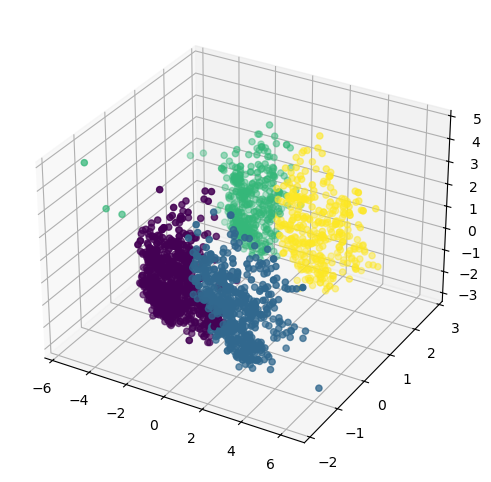

In [39]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111,projection="3d")
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c=label_agc)

In [40]:
X["cluster"] = label_agc

In [41]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,customer_tenure_days,total_spending,Total_children,Education_graduate,Education_post_graduate,Education_under_graduate,Living_with_Alone,Living_with_partner,cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='cluster', ylabel='count'>

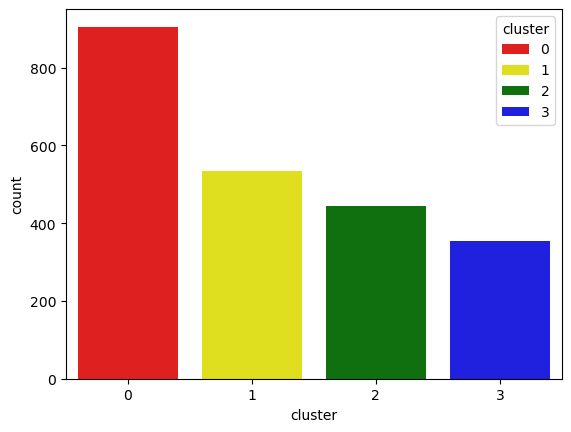

In [42]:
pal = ["red","yellow","green","blue"]

sns.countplot(x=X["cluster"],palette=pal,hue = X["cluster"])

<Axes: xlabel='total_spending', ylabel='Income'>

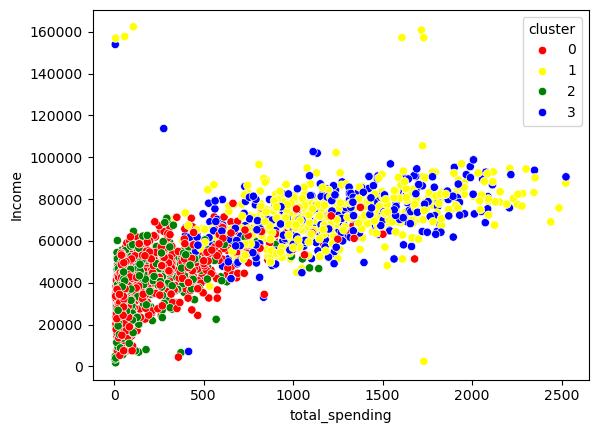

In [43]:
sns.scatterplot(x=X["total_spending"],y = X["Income"] , hue = X["cluster"] , palette = pal)

In [44]:
cluster_summary = X.groupby("cluster").mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        39680.580110  48.914917           2.594475         3.153591   
1        72808.445693  49.202247           1.958801         5.687266   
2        36960.143018  48.319820           2.594595         2.713964   
3        70722.681303  50.504249           1.855524         5.790368   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   0.969061           4.143646           6.307182  0.011050   
1                   5.498127           8.659176           3.580524  0.005618   
2                   0.837838           3.623874           6.659910  0.011261   
3                   5.014164           8.430595           3.728045  0.005666   

         Response        age  customer_tenure_days  total_spending  \
cluster         

In [46]:
import pickle

# 1. KMeans model save karein
with open("smartcart_kmeans_model.pkl", "wb") as f:
    pickle.dump(kmeans, f)

# 2. Agar aapne StandardScaler ya PCA fit kiya hai, toh use bhi save karein 
# (Misal ke taur par agar aapka PCA object 'pca' naam se hai)
with open("pca_transformer.pkl", "wb") as f:
    pickle.dump(pca, f)